In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("data/train_transaction.csv")

In [3]:
df['TransactionAmt'].describe()

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

In [4]:
# Montants : moyenne (135) ≈ 2× médiane (69), max à 464× la médiane → distribution très étalée à droite.

In [5]:
df.groupby('isFraud')['TransactionAmt'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


In [6]:
# Fraude vs légitime : fraudes un peu plus grosses (médiane 75 vs 68) mais signal faible seul.
# Les très gros montants (max fraude 5 191 vs 31 937) sont légitimes : les fraudeurs évitent d'attirer l'attention.

<Axes: >

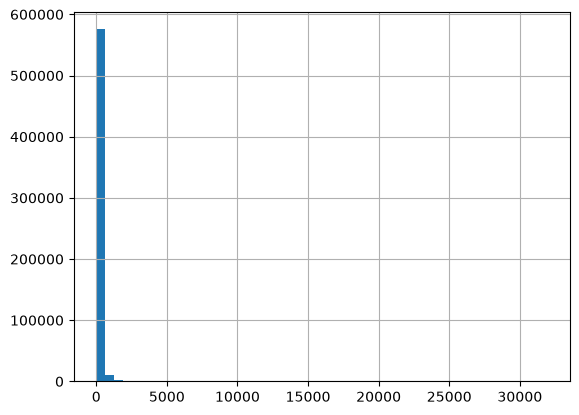

In [7]:
df['TransactionAmt'].hist(bins=50)

In [8]:
# Histogramme brut illisible (tout écrasé à gauche) — symptôme visuel de la distribution étalée.

<Axes: >

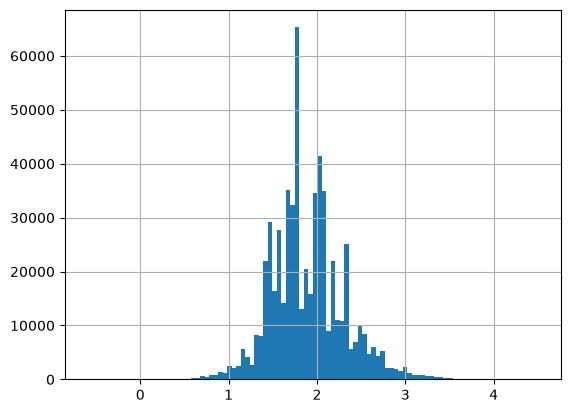

In [9]:
np.log10(df['TransactionAmt']).hist(bins=100)

In [10]:
# En log10 : quasi-cloche centrée vers 2 (≈100 €), profil log-normal classique des montants.

In [11]:
df['TransactionDT'].describe()

count    5.905400e+05
mean     7.372311e+06
std      4.617224e+06
min      8.640000e+04
25%      3.027058e+06
50%      7.306528e+06
75%      1.124662e+07
max      1.581113e+07
Name: TransactionDT, dtype: float64

In [12]:
(1.581113e+07 - 8.640000e+04)/86400

181.99918981481483

In [13]:
# TransactionDT n'est pas une date : des secondes depuis une référence cachée (min = 86 400 = pile 1 jour).
# (max-min)/86400 ≈ 182 jours : 6 mois de données ordonnées dans le temps → la validation devra être temporelle.

In [14]:
id_df = pd.read_csv('data/train_identity.csv')
id_df.shape

(144233, 41)

In [15]:
#id_df.head(10)
has_id = df['TransactionID'].isin(id_df['TransactionID'])
df.groupby(has_id)['isFraud'].mean()

TransactionID
False    0.020939
True     0.078470
Name: isFraud, dtype: float64

In [16]:
# Fraude : 2,1 % sans identity, 7,8 % avec → la présence d'identity est déjà un signal fort.

In [17]:
#fusion des tables 

df = df.merge(id_df, on='TransactionID', how='left')
df.shape

(590540, 434)

In [18]:
#séparation indices/réponses : X = les features, y = la cible.

X = df.drop(columns=['isFraud', 'TransactionID'])
y = df['isFraud']

In [19]:
#Conversion des colonnes texte pour XGBoost
for col in X.select_dtypes(exclude='number').columns:
    X[col] = X[col].astype('category')

In [20]:
df['TransactionDT'].is_monotonic_increasing

True

In [21]:
# Split temporel 80/20 

cut = int(len(X) * 0.8)
X_train, X_valid = X.iloc[:cut], X.iloc[cut:]
y_train, y_valid = y.iloc[:cut], y.iloc[cut:]
X_train.shape, X_valid.shape

((472432, 432), (118108, 432))

In [22]:
y_train.mean(), y_valid.mean()

(np.float64(0.03513521522674162), np.float64(0.034409184813899145))

In [23]:
# Baseline XGBoost: référence à battre
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    tree_method='hist',
    enable_categorical=True,
    eval_metric='aucpr',
    n_jobs=-1,
    random_state=42,
)
model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [24]:
#Eval sur le futur
from sklearn.metrics import average_precision_score

probs = model.predict_proba(X_valid)[:, 1]
average_precision_score(y_valid, probs)

0.49695562133096394

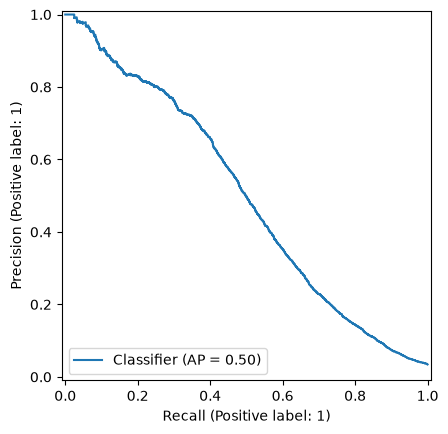

In [25]:
# Courbe precision-recall

from sklearn.metrics import PrecisionRecallDisplay
PrecisionRecallDisplay.from_predictions(y_valid, probs)

In [27]:
# Points de fonctionnement : pour un recall visé, quel seuil et quelle precision ?
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(y_valid, probs)

i = np.argmin(np.abs(recall - 0.5))
thresholds[i], precision[i], recall[i]

(np.float32(0.15631866), np.float64(0.4979171771624602), np.float64(0.5))